# Thử nghiệm dự báo độ biến động bằng XGBoost
Notebook này huấn luyện mô hình hồi quy XGBoost dạng bảng với danh sách đặc trưng và thứ tự đã cấu hình trong dự án. Nhãn là độ lệch chuẩn mẫu của lợi suất log hằng ngày trong năm phiên tiếp theo, tính theo điểm phần trăm. Đặc trưng và nhãn được dựng từ tệp OHLCV cục bộ. Các tập huấn luyện và xác thực theo thời gian được dùng để huấn luyện và chọn siêu tham số trong phạm vi giới hạn. Chỉ đánh giá tập kiểm tra sau khi đã chọn tham số.
Chạy notebook từ thư mục gốc của kho mã hoặc từ thư mục `notebooks`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.pipeline.dataset import prepare_dataset, valid_history
from src.evaluation.regression import regression_metrics

config = load_config(ROOT / "config.yaml")
ticker = config["data"].get("ticker", "ACB")
dataset = prepare_dataset(ticker, config)
history = valid_history(dataset)
print(f"Mã cổ phiếu: {ticker} | nhãn: {dataset.target} | kỳ hạn: {dataset.horizon} phiên")
print(f"Train cuối: {dataset.train.date.min().date()} -> {dataset.train.date.max().date()} | số mẫu={len(dataset.train)}")
for i, (_, validation) in enumerate(dataset.validation_folds, start=1):
    print(f"Validation fold {i}: {validation.date.min().date()} -> {validation.date.max().date()} | số mẫu={len(validation)}")
print(f"Test: {dataset.test.date.min().date()} -> {dataset.test.date.max().date()} | số mẫu={len(dataset.test)}")


Mã cổ phiếu: ACB | nhãn: target_volatility_5d | kỳ hạn: 5 phiên
Train cuối: 2018-12-28 -> 2025-08-01 | số mẫu=1639
Validation fold 1: 2023-02-02 -> 2023-07-31 | số mẫu=125
Validation fold 2: 2023-08-01 -> 2024-01-25 | số mẫu=125
Validation fold 3: 2024-01-26 -> 2024-07-31 | số mẫu=125
Validation fold 4: 2024-08-01 -> 2025-02-03 | số mẫu=125
Validation fold 5: 2025-02-04 -> 2025-08-01 | số mẫu=125
Test: 2025-08-11 -> 2026-10-12 | số mẫu=291


## Chọn tham số bằng tập xác thực và huấn luyện mô hình
Mỗi hàm bên dưới nhận đúng một tham số đang được khảo sát. Các tham số còn lại của XGBoost được để mặc định; `random_state=42` và `n_jobs=2` được cố định để kết quả có thể lặp lại và giới hạn tài nguyên (riêng hàm `n_jobs_error` thay đổi `n_jobs`). Mỗi hàm trả Training Error và Validation Error là RMSE trung bình qua các fold. Hãy xem từng bảng/biểu đồ, rồi tự ghép các giá trị đã chọn ở cell kế tiếp.


n_estimators


,n_estimators,Training Error,Validation Error
0,1,"[0.7060004754281952, 0.7306921522595541, 0.739...","[1.836787379261856, 1.5417639854044827, 1.3687..."
1,3,"[0.4050207353209643, 0.4425944302025425, 0.464...","[1.3851319592604943, 1.4473573752701285, 1.118..."
2,5,"[0.2651316561635262, 0.29751491561025745, 0.29...","[1.0685211885231531, 1.8673773153969344, 1.356..."
3,7,"[0.19975255544581416, 0.22407067023048832, 0.2...","[1.0503487069562445, 1.9946814301957134, 1.381..."
4,9,"[0.15372851728122972, 0.16643260510414615, 0.1...","[1.133865370828234, 1.984578838709691, 1.37448..."
5,11,"[0.13393255188731257, 0.13124876990307055, 0.1...","[1.1329752733891127, 2.018057007573691, 1.3617..."
6,13,"[0.10545394112343276, 0.10822146949002176, 0.1...","[1.159298563043343, 2.0530352009747945, 1.3681..."
7,15,"[0.0906195087575764, 0.0925849835578133, 0.102...","[1.1456157592642022, 2.235821632568188, 1.5617..."
8,17,"[0.07550124955585724, 0.07893758218444535, 0.0...","[1.1481468662694054, 2.420655885863203, 1.5870..."
9,19,"[0.06557272577357576, 0.07119124346116146, 0.0...","[1.1187011493740882, 2.480944980160145, 1.6045..."


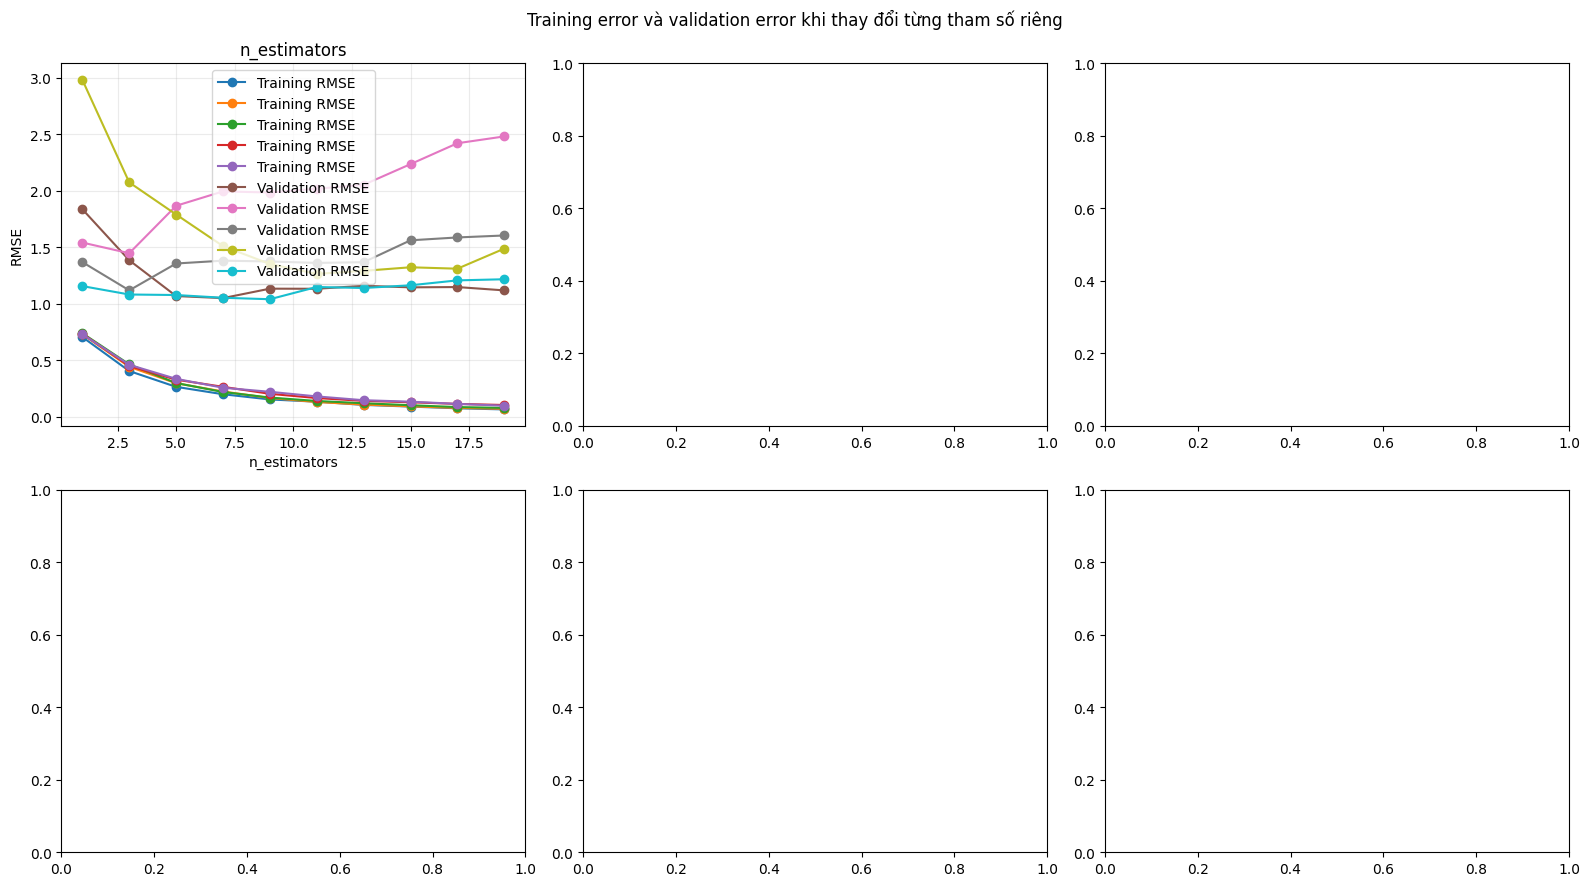

(<Figure size 1600x900 with 6 Axes>,
 array([[<Axes: title={'center': 'n_estimators'}, xlabel='n_estimators', ylabel='RMSE'>,
         <Axes: >, <Axes: >],
        [<Axes: >, <Axes: >, <Axes: >]], dtype=object))

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from src.pipeline.dataset import feature_matrix
from src.models.xgboost_model import XGBoostModel

base_params = dict(config["models"]["xgboost"])


def _single_parameter_error(parameter_name, value):
    """Vary one XGBoost parameter; leave all other model parameters at defaults."""
    model_params = {parameter_name: value}
    if parameter_name != "n_jobs":
        model_params["n_jobs"] = 2
    train_errors, validation_errors = [], []
    for train, validation in dataset.validation_folds:
        x_train = feature_matrix(train, dataset.features)
        y_train = train[dataset.target].to_numpy(dtype=float)
        x_validation = feature_matrix(validation, dataset.features)
        y_validation = validation[dataset.target].to_numpy(dtype=float)
        model = XGBRegressor(random_state=42, objective="reg:squarederror", **model_params)
        model.fit(x_train, y_train)
        train_prediction = np.maximum(model.predict(x_train), 0)
        validation_prediction = np.maximum(model.predict(x_validation), 0)
        train_errors.append(float(np.sqrt(mean_squared_error(y_train, train_prediction))))
        validation_errors.append(float(np.sqrt(mean_squared_error(y_validation, validation_prediction))))
    return {
        parameter_name: value,
        "Training Error": float(np.mean(train_errors)),
        "Validation Error": float(np.mean(validation_errors)),
    }


def n_estimators_error(es):
    return _single_parameter_error("n_estimators", es)


def max_depth_error(depth):
    return _single_parameter_error("max_depth", depth)


def learning_rate_error(rate):
    return _single_parameter_error("learning_rate", rate)


def subsample_error(sample_rate):
    return _single_parameter_error("subsample", sample_rate)


def colsample_bytree_error(column_rate):
    return _single_parameter_error("colsample_bytree", column_rate)


def n_jobs_error(jobs):
    return _single_parameter_error("n_jobs", jobs)


parameter_functions = {
    "n_estimators": (n_estimators_error, np.arange(1,20,2)),
    "max_depth": (max_depth_error, [2, 3, 4]),
    "learning_rate": (learning_rate_error, [0.03, 0.05, 0.08]),
    "subsample": (subsample_error, [0.7, 0.9, 1.0]),
    "colsample_bytree": (colsample_bytree_error, [0.7, 0.9, 1.0]),
    "n_jobs": (n_jobs_error, [1, 2, 4]),
}
parameter_results = {
    name: [evaluate(value) for value in values]
    for name, (evaluate, values) in parameter_functions.items()
}
for name, rows in parameter_results.items():
    print(f"\n{name}")
    display(pd.DataFrame(rows))


def plot_parameter_errors(results_by_parameter):
    """Plot training and validation RMSE for each one-parameter sweep."""
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, (name, rows) in zip(axes.ravel(), results_by_parameter.items()):
        values = [row[name] for row in rows]
        ax.plot(values, [row["Training Error"] for row in rows], marker="o", label="Training RMSE")
        ax.plot(values, [row["Validation Error"] for row in rows], marker="o", label="Validation RMSE")
        ax.set_title(name)
        ax.set_xlabel(name)
        ax.set_ylabel("RMSE")
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle("Training error và validation error khi thay đổi từng tham số riêng")
    fig.tight_layout()
    plt.show()
    return fig, axes


plot_parameter_errors(parameter_results)


XGBoostError: Invalid Parameter format for max_depth expect int but value='[1, 3, 5, 7, 9, 11, 13, 15, 17, 19]'

## Ghép tham số đã chọn và huấn luyện mô hình
Sau khi đọc kết quả của từng lần quét riêng, sửa các giá trị trong `selected_params` theo lựa chọn của bạn. Cell này sẽ fit mô hình cuối trên toàn bộ tập train trước test.

In [3]:
selected_params = {
    "n_estimators": base_params["n_estimators"],
    "max_depth": base_params["max_depth"],
    "learning_rate": base_params["learning_rate"],
    "subsample": base_params["subsample"],
    "colsample_bytree": base_params["colsample_bytree"],
    "n_jobs": 2,
}

model = XGBoostModel(
    dataset.features, dataset.target, dataset.horizon,
    params=selected_params, seed=config["seed"],
).fit(dataset.train)
print("Tham số đang dùng:", selected_params)


Tham số đang dùng: {'n_estimators': 160, 'max_depth': 3, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'n_jobs': 2}


## Đánh giá trên tập kiểm tra độc lập
Dự báo độ biến động được chặn dưới tại 0. Có thể dùng `predict_raw` để xem giá trị hồi quy thô. Nhãn không được đưa vào ma trận đặc trưng.

In [4]:
test_forecast = model.predict(history, dataset.test["date"])
actual = dataset.test[["date", dataset.target]].rename(columns={dataset.target: "actual_volatility"})
comparison = actual.merge(test_forecast, on="date", validate="one_to_one")
metrics = regression_metrics(comparison["actual_volatility"], comparison["predicted_volatility"])
print("Tham số đã ghép:", selected_params)
print("Các chỉ số trên tập kiểm tra độc lập:", metrics)
comparison.head()


Tham số đã ghép: {'n_estimators': 160, 'max_depth': 3, 'learning_rate': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'n_jobs': 2}
Các chỉ số trên tập kiểm tra độc lập: {'mae': 1.137144091282971, 'rmse': 1.343884037338624, 'r2': -1.3129537708352652, 'samples': 291}


,date,actual_volatility,model,predicted_volatility,raw_prediction
0,2025-08-11,2.745265,xgboost,1.887629,1.887629
1,2025-08-12,2.513354,xgboost,1.950361,1.950361
2,2025-08-13,3.251424,xgboost,1.954510,1.954510
3,2025-08-14,2.796236,xgboost,1.929314,1.929314
4,2025-08-15,4.555686,xgboost,1.891919,1.891919


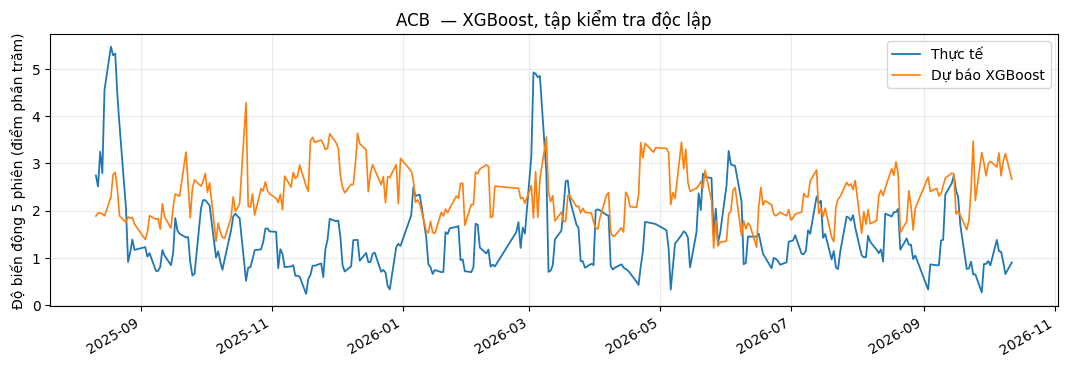

In [5]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(comparison["date"], comparison["actual_volatility"], label="Thực tế", linewidth=1.3)
ax.plot(comparison["date"], comparison["predicted_volatility"], label="Dự báo XGBoost", linewidth=1.2)
ax.set(title=f"{ticker}  — XGBoost, tập kiểm tra độc lập", ylabel="Độ biến động 5 phiên (điểm phần trăm)")
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); plt.show()

## Mức độ quan trọng của đặc trưng
Mức độ quan trọng của cây là thông tin chẩn đoán mô hình, không thể hiện quan hệ nhân quả. Giá trị này có thể thiếu ổn định giữa các đặc trưng trung bình trượt có tương quan. Biểu đồ thể hiện mức độ quan trọng theo số lần phân tách do mô hình XGBoost đã huấn luyện báo cáo.

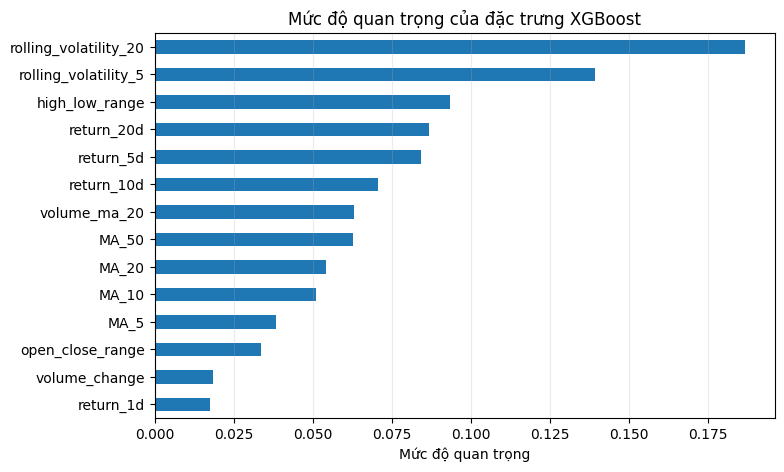

In [6]:
importance = pd.Series(
    model.estimator.feature_importances_, index=dataset.features, name="mức độ quan trọng"
).sort_values()
ax = importance.plot.barh(figsize=(8, 5), title="Mức độ quan trọng của đặc trưng XGBoost")
ax.set_xlabel("Mức độ quan trọng"); ax.grid(axis="x", alpha=.25); plt.show()

## Kiểm tra phần dư
Quan sát xem sai số có thay đổi có hệ thống theo độ biến động thực tế hay không. Đây chỉ là mô tả; tập kiểm tra độc lập vẫn là cơ sở duy nhất để đánh giá hiệu năng cuối cùng.

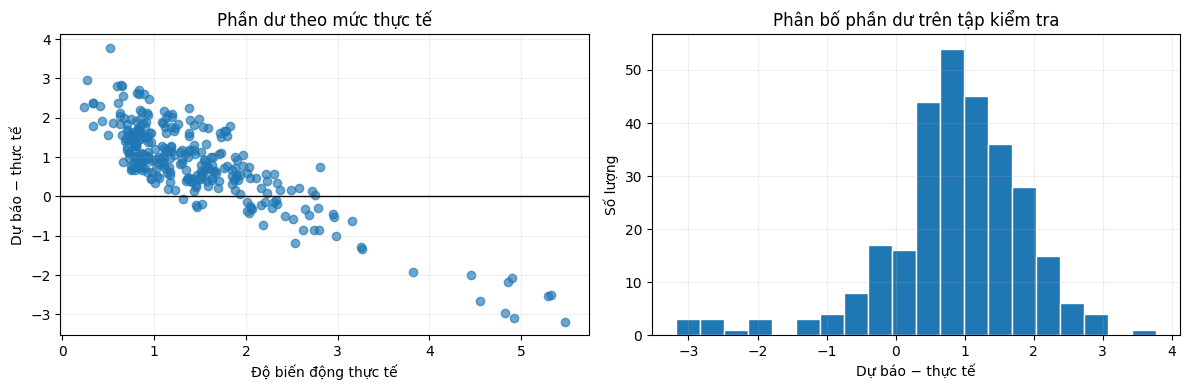

In [7]:
comparison["residual"] = comparison["predicted_volatility"] - comparison["actual_volatility"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(comparison["actual_volatility"], comparison["residual"], alpha=.65)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="Độ biến động thực tế", ylabel="Dự báo − thực tế", title="Phần dư theo mức thực tế")
axes[1].hist(comparison["residual"], bins=20, edgecolor="white")
axes[1].set(xlabel="Dự báo − thực tế", ylabel="Số lượng", title="Phân bố phần dư trên tập kiểm tra")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## Tổng kết
Mỗi hàm chỉ thay đổi một tham số; các tham số khác để mặc định, ngoại trừ `n_jobs=2` được cố định cho các hàm còn lại. Training Error là RMSE in-sample trên fold train; Validation Error là RMSE ngoài mẫu. Chọn giá trị riêng cho từng tham số từ các biểu đồ, ghép thủ công ở cell trước khi huấn luyện mô hình cuối. Tập kiểm tra độc lập chỉ dùng để báo cáo kết quả cuối cùng.